import the libraries used throughout the notebook

In [1]:
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.decomposition import PCA

set deterministic seeds for numpy and torch

In [2]:
SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)

define the fixed graph as an adjacency matrix

In [3]:
A = np.array([
    [0,1,0,0,1,0],
    [1,0,1,1,1,0],
    [0,1,0,1,0,1],
    [0,1,1,0,1,1],
    [1,1,0,1,0,1],
    [0,0,1,1,1,0]
])

verify that the adjacency matrix is symmetric

In [4]:
assert np.array_equal(A, A.T)
A

array([[0, 1, 0, 0, 1, 0],
       [1, 0, 1, 1, 1, 0],
       [0, 1, 0, 1, 0, 1],
       [0, 1, 1, 0, 1, 1],
       [1, 1, 0, 1, 0, 1],
       [0, 0, 1, 1, 1, 0]])

compute the number of nodes and the number of edges

In [5]:
num_nodes = A.shape[0]
num_edges = int(A.sum() / 2)
num_nodes, num_edges

(6, 10)

compute the degree vector

In [6]:
degree_vector = A.sum(axis=1)
degree_vector

array([2, 4, 3, 4, 4, 3])

verify the degree vector against the expected values

In [7]:
expected_degrees = np.array([2, 4, 3, 4, 4, 3])
assert np.array_equal(degree_vector, expected_degrees)
degree_vector

array([2, 4, 3, 4, 4, 3])

construct the degree matrix

In [8]:
D = np.diag(degree_vector)
D

array([[2, 0, 0, 0, 0, 0],
       [0, 4, 0, 0, 0, 0],
       [0, 0, 3, 0, 0, 0],
       [0, 0, 0, 4, 0, 0],
       [0, 0, 0, 0, 4, 0],
       [0, 0, 0, 0, 0, 3]])

build the neighbor list for every node

In [9]:
def build_neighbor_list(A):
    num_nodes = A.shape[0]
    neighbor_list = {node: np.where(A[node] == 1)[0].tolist() for node in range(num_nodes)}
    return neighbor_list

In [10]:
neighbor_list = build_neighbor_list(A)
neighbor_list

{0: [1, 4],
 1: [0, 2, 3, 4],
 2: [1, 3, 5],
 3: [1, 2, 4, 5],
 4: [0, 1, 3, 5],
 5: [2, 3, 4]}

build the edge list from the adjacency matrix

In [11]:
def build_edge_list(A):
    num_nodes = A.shape[0]
    edge_list = [(i, j) for i in range(num_nodes) for j in range(i + 1, num_nodes) if A[i, j] == 1]
    return edge_list

In [12]:
edge_list = build_edge_list(A)
assert num_edges == len(edge_list)
edge_list, len(edge_list)

([(0, 1),
  (0, 4),
  (1, 2),
  (1, 3),
  (1, 4),
  (2, 3),
  (2, 5),
  (3, 4),
  (3, 5),
  (4, 5)],
 10)

print basic graph statistics

In [13]:
print("num_nodes", num_nodes)
print("num_edges", num_edges)
print("degree_vector", degree_vector)
print("neighbor_list", neighbor_list)

num_nodes 6
num_edges 10
degree_vector [2 4 3 4 4 3]
neighbor_list {0: [1, 4], 1: [0, 2, 3, 4], 2: [1, 3, 5], 3: [1, 2, 4, 5], 4: [0, 1, 3, 5], 5: [2, 3, 4]}


convert the adjacency matrix into a row-normalized transition matrix

In [14]:
def transition_matrix(A):
    degree_vector = A.sum(axis=1)
    D_inv = np.diag(1.0 / degree_vector)
    P = D_inv @ A
    return P

In [15]:
P = transition_matrix(A)
P

array([[0.        , 0.5       , 0.        , 0.        , 0.5       ,
        0.        ],
       [0.25      , 0.        , 0.25      , 0.25      , 0.25      ,
        0.        ],
       [0.        , 0.33333333, 0.        , 0.33333333, 0.        ,
        0.33333333],
       [0.        , 0.25      , 0.25      , 0.        , 0.25      ,
        0.25      ],
       [0.25      , 0.25      , 0.        , 0.25      , 0.        ,
        0.25      ],
       [0.        , 0.        , 0.33333333, 0.33333333, 0.33333333,
        0.        ]])

verify that every row of the transition matrix sums to one

In [16]:
assert np.allclose(P.sum(axis=1), 1)
P.sum(axis=1)

array([1., 1., 1., 1., 1., 1.])

verify specific transition probabilities for node 0

In [17]:
assert np.isclose(P[0, 1], 0.5)
assert np.isclose(P[0, 4], 0.5)
P[0]

array([0. , 0.5, 0. , 0. , 0.5, 0. ])

verify that zero entries in the adjacency matrix remain zero in the transition matrix

In [18]:
assert np.all((A == 0) == (P == 0))

implement a single random walk using the transition matrix

In [19]:
def random_walk(start_node, walk_length, P):
    walk = [start_node]
    current_node = start_node
    for step in range(walk_length - 1):
        probabilities = P[current_node]
        next_node = np.random.choice(len(probabilities), p=probabilities)
        walk.append(next_node)
        current_node = next_node
    return walk

generate one example random walk

In [20]:
example_walk = random_walk(0, 10, P)
example_walk

[0, 1, 4, 3, 4, 0, 1, 0, 4, 3]

generate multiple random walks from the same start node

In [21]:
multiple_walks = [random_walk(0, 10, P) for _ in range(5)]
multiple_walks

[[0, 4, 0, 4, 5, 2, 1, 0, 1, 3],
 [0, 1, 2, 3, 1, 2, 3, 2, 5, 2],
 [0, 4, 3, 1, 3, 1, 0, 4, 5, 4],
 [0, 1, 0, 4, 1, 0, 1, 0, 4, 1],
 [0, 4, 1, 3, 4, 0, 4, 5, 4, 5]]

generate one walk from every starting node

In [22]:
walks_from_every_node = [random_walk(node, 10, P) for node in range(num_nodes)]
walks_from_every_node

[[0, 4, 5, 2, 1, 0, 1, 2, 1, 4],
 [1, 2, 1, 3, 1, 4, 0, 4, 5, 2],
 [2, 1, 4, 3, 4, 5, 2, 3, 1, 4],
 [3, 4, 1, 0, 1, 2, 5, 3, 5, 3],
 [4, 0, 4, 5, 3, 5, 3, 4, 1, 0],
 [5, 2, 1, 3, 2, 3, 5, 2, 3, 5]]

verify that every transition in a walk corresponds to an actual graph edge

In [23]:
def walk_transitions_are_valid(walk, A):
    for i in range(len(walk) - 1):
        if A[walk[i], walk[i + 1]] == 0:
            return False
    return True

In [24]:
assert all(walk_transitions_are_valid(walk, A) for walk in walks_from_every_node)

estimate empirical transition probabilities from a collection of random walks

In [25]:
def empirical_transition_matrix(walks, num_nodes):
    counts = np.zeros((num_nodes, num_nodes))
    for walk in walks:
        for i in range(len(walk) - 1):
            counts[walk[i], walk[i + 1]] += 1
    row_sums = counts.sum(axis=1, keepdims=True)
    row_sums[row_sums == 0] = 1
    empirical_P = counts / row_sums
    return empirical_P

generate many random walks for empirical estimation

In [26]:
many_walks = [random_walk(node, 50, P) for node in range(num_nodes) for _ in range(200)]
len(many_walks)

1200

compare the theoretical and empirical transition matrices

In [27]:
empirical_P = empirical_transition_matrix(many_walks, num_nodes)
print(P)
print(empirical_P)
print(np.abs(P - empirical_P))

[[0.         0.5        0.         0.         0.5        0.        ]
 [0.25       0.         0.25       0.25       0.25       0.        ]
 [0.         0.33333333 0.         0.33333333 0.         0.33333333]
 [0.         0.25       0.25       0.         0.25       0.25      ]
 [0.25       0.25       0.         0.25       0.         0.25      ]
 [0.         0.         0.33333333 0.33333333 0.33333333 0.        ]]
[[0.         0.4954576  0.         0.         0.5045424  0.        ]
 [0.24846469 0.         0.25162061 0.25068236 0.24923234 0.        ]
 [0.         0.33087484 0.         0.34006581 0.         0.32905934]
 [0.         0.25281804 0.24883465 0.         0.24841088 0.24993644]
 [0.25083184 0.25023462 0.         0.24929614 0.         0.2496374 ]
 [0.         0.         0.33060575 0.33742471 0.33196954 0.        ]]
[[0.00000000e+00 4.54239569e-03 0.00000000e+00 0.00000000e+00
  4.54239569e-03 0.00000000e+00]
 [1.53531218e-03 0.00000000e+00 1.62060730e-03 6.82360969e-04
  7.67656090e

a squared counts two step walks while p squared gives two step transition probabilities

In [28]:
A_squared = A @ A
P_squared = P @ P
print(A_squared)
print(P_squared)

[[2 1 1 2 1 1]
 [1 4 1 2 2 3]
 [1 1 3 2 3 1]
 [2 2 2 4 2 2]
 [1 2 3 2 4 1]
 [1 3 1 2 1 3]]
[[0.25       0.125      0.125      0.25       0.125      0.125     ]
 [0.0625     0.33333333 0.0625     0.14583333 0.1875     0.20833333]
 [0.08333333 0.08333333 0.27777778 0.19444444 0.27777778 0.08333333]
 [0.125      0.14583333 0.14583333 0.29166667 0.14583333 0.14583333]
 [0.0625     0.1875     0.20833333 0.14583333 0.33333333 0.0625    ]
 [0.08333333 0.27777778 0.08333333 0.19444444 0.08333333 0.27777778]]


estimate empirical two step transition frequencies from the same random walks

In [29]:
def empirical_two_step_transition_matrix(walks, num_nodes):
    counts = np.zeros((num_nodes, num_nodes))
    for walk in walks:
        for i in range(len(walk) - 2):
            counts[walk[i], walk[i + 2]] += 1
    row_sums = counts.sum(axis=1, keepdims=True)
    row_sums[row_sums == 0] = 1
    empirical_P2 = counts / row_sums
    return empirical_P2

compare empirical two step transition frequencies with p squared

In [30]:
empirical_P2 = empirical_two_step_transition_matrix(many_walks, num_nodes)
print(P_squared)
print(empirical_P2)
print(np.abs(P_squared - empirical_P2))

[[0.25       0.125      0.125      0.25       0.125      0.125     ]
 [0.0625     0.33333333 0.0625     0.14583333 0.1875     0.20833333]
 [0.08333333 0.08333333 0.27777778 0.19444444 0.27777778 0.08333333]
 [0.125      0.14583333 0.14583333 0.29166667 0.14583333 0.14583333]
 [0.0625     0.1875     0.20833333 0.14583333 0.33333333 0.0625    ]
 [0.08333333 0.27777778 0.08333333 0.19444444 0.08333333 0.27777778]]
[[0.25159181 0.12940974 0.12510755 0.24849424 0.12355877 0.12183789]
 [0.06478261 0.32956522 0.06234783 0.14591304 0.18686957 0.21052174]
 [0.08240741 0.08599537 0.27083333 0.19930556 0.27719907 0.08425926]
 [0.12666667 0.1425974  0.15134199 0.29194805 0.14398268 0.1434632 ]
 [0.06118714 0.1894012  0.2084895  0.14730236 0.33199686 0.06162294]
 [0.07894737 0.28089497 0.08242523 0.19313703 0.08590308 0.27869233]]
[[1.59180864e-03 4.40974015e-03 1.07554638e-04 1.50576493e-03
  1.44123215e-03 3.16210635e-03]
 [2.28260870e-03 3.76811594e-03 1.52173913e-04 7.97101449e-05
  6.30434783e

generate context pairs from a single walk using a symmetric window

In [31]:
def generate_context_pairs(walk, window_size):
    pairs = []
    for center_position in range(len(walk)):
        center_node = walk[center_position]
        left_bound = max(0, center_position - window_size)
        right_bound = min(len(walk), center_position + window_size + 1)
        for context_position in range(left_bound, right_bound):
            if context_position != center_position:
                pairs.append((center_node, walk[context_position]))
    return pairs

test the context pair function on a tiny walk before using many walks

In [32]:
tiny_walk = [0, 1, 2, 3, 4]
generate_context_pairs(tiny_walk, 2)

[(0, 1),
 (0, 2),
 (1, 0),
 (1, 2),
 (1, 3),
 (2, 0),
 (2, 1),
 (2, 3),
 (2, 4),
 (3, 1),
 (3, 2),
 (3, 4),
 (4, 2),
 (4, 3)]

generate context pairs from many walks

In [33]:
def generate_pairs_from_walks(walks, window_size):
    all_pairs = []
    for walk in walks:
        all_pairs.extend(generate_context_pairs(walk, window_size))
    return all_pairs

inspect the number of walks and the number of context pairs

In [34]:
sample_pairs = generate_pairs_from_walks(walks_from_every_node, window_size=2)
print("number of walks", len(walks_from_every_node))
print("number of context pairs", len(sample_pairs))
print("first pairs", sample_pairs[:10])

number of walks 6
number of context pairs 204
first pairs [(0, 4), (0, 5), (4, 0), (4, 5), (4, 2), (5, 0), (5, 4), (5, 2), (5, 1), (2, 4)]


a center node has a positive context from its walk window and a negative context sampled elsewhere

In [35]:
example_center_node = 0
example_positive_context = 1
example_negative_context = 5
print("center node", example_center_node)
print("positive context", example_positive_context)
print("negative context", example_negative_context)

center node 0
positive context 1
negative context 5


the skip-gram score is a dot product between a center vector and a context vector

In [36]:
def dot_score(center_vector, context_vector):
    return np.dot(center_vector, context_vector)

demonstrate the dot product score with example vectors

In [37]:
example_center_vector = np.array([0.2, -0.1, 0.4, 0.05])
example_context_vector = np.array([0.1, 0.3, -0.2, 0.15])
dot_score(example_center_vector, example_context_vector)

np.float64(-0.0825)

the sigmoid function converts a score into a probability

In [38]:
def sigmoid(x):
    return 1.0 / (1.0 + np.exp(-x))

demonstrate the sigmoid function on the example score

In [39]:
example_score = dot_score(example_center_vector, example_context_vector)
sigmoid(example_score)

np.float64(0.47938669028555136)

sample a single negative node that is not equal to the positive context

In [40]:
def sample_negative_node(num_nodes, positive_node):
    negative_node = np.random.randint(num_nodes)
    while negative_node == positive_node:
        negative_node = np.random.randint(num_nodes)
    return negative_node

demonstrate a center positive negative triple

In [41]:
demo_center = 0
demo_positive = 1
demo_negative = sample_negative_node(num_nodes, demo_positive)
demo_center, demo_positive, demo_negative

(0, 1, 4)

sample multiple negative nodes for one positive context

In [42]:
def sample_negative_nodes(num_nodes, positive_node, num_negative_samples):
    negative_nodes = []
    while len(negative_nodes) < num_negative_samples:
        candidate = np.random.randint(num_nodes)
        if candidate != positive_node:
            negative_nodes.append(candidate)
    return negative_nodes

demonstrate negative sampling with k equal to one

In [43]:
sample_negative_nodes(num_nodes, demo_positive, 1)

[3]

demonstrate negative sampling with k equal to five

In [44]:
sample_negative_nodes(num_nodes, demo_positive, 5)

[4, 3, 3, 3, 2]

implement the naive numpy skip-gram negative sampling loss

In [45]:
def skipgram_loss_numpy(positive_score, negative_scores):
    positive_term = -np.log(sigmoid(positive_score))
    negative_term = -np.sum(np.log(sigmoid(-np.array(negative_scores))))
    return positive_term + negative_term

demonstrate the naive numpy loss on example scores

In [46]:
example_positive_score = 1.2
example_negative_scores = [-0.3, 0.1, -0.8]
skipgram_loss_numpy(example_positive_score, example_negative_scores)

np.float64(1.9331350378279069)

negative log sigmoid of x equals softplus of negative x

In [47]:
example_x = 1.2
naive_value = -np.log(sigmoid(example_x))
stable_value = F.softplus(torch.tensor(-example_x)).item()
naive_value, stable_value

(np.float64(0.26328246733803135), 0.26328244805336)

implement the numerically stable pytorch skip-gram negative sampling loss

In [48]:
def skipgram_loss_torch(positive_score, negative_scores):
    positive_term = F.softplus(-positive_score)
    negative_term = F.softplus(negative_scores).sum(dim=-1)
    return positive_term + negative_term

demonstrate the pytorch loss on example tensors

In [49]:
example_positive_score_t = torch.tensor(1.2)
example_negative_scores_t = torch.tensor([-0.3, 0.1, -0.8])
skipgram_loss_torch(example_positive_score_t, example_negative_scores_t)

tensor(1.9331)

create a pytorch embedding table for the graph nodes

In [50]:
embedding_dim_demo = 4
demo_embedding = nn.Embedding(num_nodes, embedding_dim_demo)
demo_embedding

Embedding(6, 4)

compare indexing the weight matrix directly with calling the embedding module

In [51]:
demo_embedding.weight[0], demo_embedding(torch.tensor(0))

(tensor([ 1.9269,  1.4873,  0.9007, -2.1055], grad_fn=<SelectBackward0>),
 tensor([ 1.9269,  1.4873,  0.9007, -2.1055], grad_fn=<EmbeddingBackward0>))

demonstrate batched embedding lookup for multiple nodes

In [52]:
batched_lookup = demo_embedding(torch.tensor([0, 2, 4]))
batched_lookup

tensor([[ 1.9269,  1.4873,  0.9007, -2.1055],
        [ 0.3559, -0.6866, -0.4934,  0.2415],
        [-0.3097, -0.3957,  0.8034, -0.6216]], grad_fn=<EmbeddingBackward0>)

verify the input shape the output shape and the embedding dimension

In [53]:
input_ids = torch.tensor([0, 2, 4])
output_vectors = demo_embedding(input_ids)
print("input shape", input_ids.shape)
print("output shape", output_vectors.shape)
print("embedding dimension", demo_embedding.embedding_dim)

input shape torch.Size([3])
output shape torch.Size([3, 4])
embedding dimension 4


define the skip-gram model with separate center and context embedding tables

In [54]:
class SkipGram(nn.Module):
    def __init__(self, num_nodes, embedding_dim):
        super().__init__()
        self.center_embeddings = nn.Embedding(num_nodes, embedding_dim)
        self.context_embeddings = nn.Embedding(num_nodes, embedding_dim)

    def forward(self, center_nodes, positive_nodes, negative_nodes):
        center_vectors = self.center_embeddings(center_nodes)
        positive_vectors = self.context_embeddings(positive_nodes)
        negative_vectors = self.context_embeddings(negative_nodes)
        positive_scores = torch.sum(center_vectors * positive_vectors, dim=-1)
        negative_scores = torch.bmm(negative_vectors, center_vectors.unsqueeze(-1)).squeeze(-1)
        positive_loss = F.softplus(-positive_scores)
        negative_loss = F.softplus(negative_scores).sum(dim=-1)
        total_loss = (positive_loss + negative_loss).mean()
        return total_loss

run a forward pass on a tiny batch where only a few nodes are involved

In [55]:
demo_model = SkipGram(num_nodes, embedding_dim=4)
demo_center_nodes = torch.tensor([0])
demo_positive_nodes = torch.tensor([1])
demo_negative_nodes = torch.tensor([[2, 3, 4]])
demo_loss = demo_model(demo_center_nodes, demo_positive_nodes, demo_negative_nodes)
demo_loss

tensor(2.1763, grad_fn=<MeanBackward0>)

backpropagate through the skip-gram loss

In [56]:
demo_loss.backward()

inspect gradient shapes and gradient norms for both embedding tables

In [57]:
center_grad = demo_model.center_embeddings.weight.grad
context_grad = demo_model.context_embeddings.weight.grad
print("center grad shape", center_grad.shape)
print("center grad norm", center_grad.norm().item())
print("context grad shape", context_grad.shape)
print("context grad norm", context_grad.norm().item())

center grad shape torch.Size([6, 4])
center grad norm 1.1984772682189941
context grad shape torch.Size([6, 4])
context grad norm 1.5906590223312378


verify that only the nodes involved in the batch receive nonzero gradients

In [58]:
per_node_center_grad_norm = center_grad.norm(dim=1)
per_node_context_grad_norm = context_grad.norm(dim=1)
for node in range(num_nodes):
    print(node, "center", per_node_center_grad_norm[node].item(), "context", per_node_context_grad_norm[node].item())

0 center 1.1984772682189941 context 0.0
1 center 0.0 context 0.22822782397270203
2 center 0.0 context 1.23628568649292
3 center 0.0 context 0.31269270181655884
4 center 0.0 context 0.9230003356933594
5 center 0.0 context 0.0


generate deepwalk training pairs from many random walks

In [59]:
def generate_deepwalk_pairs(P, num_nodes, num_walks, walk_length, window_size):
    walks = []
    for _ in range(num_walks):
        for start_node in range(num_nodes):
            walks.append(random_walk(start_node, walk_length, P))
    pairs = generate_pairs_from_walks(walks, window_size)
    return walks, pairs

define deepwalk training hyperparameters explicitly

In [60]:
embedding_dim = 8
num_walks = 20
walk_length = 20
window_size = 2
num_negative_samples = 5
learning_rate = 0.01
epochs = 100
batch_size = 32

implement the deepwalk training loop using the skip-gram model

In [61]:
def train_deepwalk(pairs, num_nodes, embedding_dim, num_negative_samples, learning_rate, epochs, batch_size):
    model = SkipGram(num_nodes, embedding_dim)
    optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)
    pairs_array = np.array(pairs)
    history = {"epoch": [], "average_loss": [], "average_positive_score": [], "average_negative_score": []}
    for epoch in range(epochs):
        permutation = np.random.permutation(len(pairs_array))
        shuffled_pairs = pairs_array[permutation]
        epoch_losses = []
        epoch_positive_scores = []
        epoch_negative_scores = []
        for start in range(0, len(shuffled_pairs), batch_size):
            batch = shuffled_pairs[start:start + batch_size]
            center_nodes = torch.tensor(batch[:, 0], dtype=torch.long)
            positive_nodes = torch.tensor(batch[:, 1], dtype=torch.long)
            negative_nodes = torch.tensor(
                [sample_negative_nodes(num_nodes, positive_node, num_negative_samples) for positive_node in batch[:, 1]],
                dtype=torch.long
            )
            optimizer.zero_grad()
            loss = model(center_nodes, positive_nodes, negative_nodes)
            loss.backward()
            optimizer.step()
            with torch.no_grad():
                center_vectors = model.center_embeddings(center_nodes)
                positive_vectors = model.context_embeddings(positive_nodes)
                negative_vectors = model.context_embeddings(negative_nodes)
                positive_scores = torch.sum(center_vectors * positive_vectors, dim=-1)
                negative_scores = torch.bmm(negative_vectors, center_vectors.unsqueeze(-1)).squeeze(-1)
            epoch_losses.append(loss.item())
            epoch_positive_scores.append(positive_scores.mean().item())
            epoch_negative_scores.append(negative_scores.mean().item())
        history["epoch"].append(epoch)
        history["average_loss"].append(float(np.mean(epoch_losses)))
        history["average_positive_score"].append(float(np.mean(epoch_positive_scores)))
        history["average_negative_score"].append(float(np.mean(epoch_negative_scores)))
    return model, history

generate deepwalk walks and context pairs using the baseline hyperparameters

In [62]:
deepwalk_walks, deepwalk_pairs = generate_deepwalk_pairs(P, num_nodes, num_walks, walk_length, window_size)
len(deepwalk_walks), len(deepwalk_pairs)

(120, 8880)

reset the seeds and train the deepwalk skip-gram model

In [63]:
np.random.seed(SEED)
torch.manual_seed(SEED)
deepwalk_model, deepwalk_history = train_deepwalk(deepwalk_pairs, num_nodes, embedding_dim, num_negative_samples, learning_rate, epochs, batch_size)

plot the deepwalk training loss curve

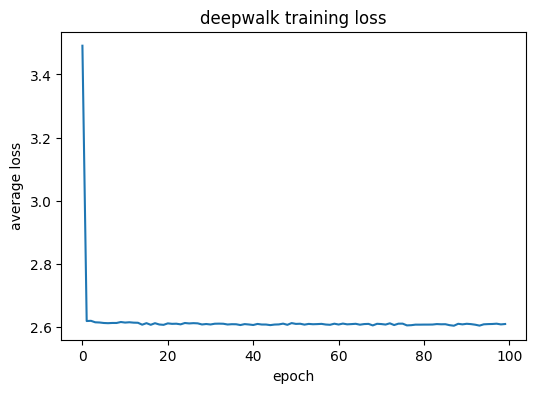

In [64]:
plt.figure(figsize=(6, 4))
plt.plot(deepwalk_history["epoch"], deepwalk_history["average_loss"])
plt.xlabel("epoch")
plt.ylabel("average loss")
plt.title("deepwalk training loss")
plt.show()

plot the average positive and negative scores across training

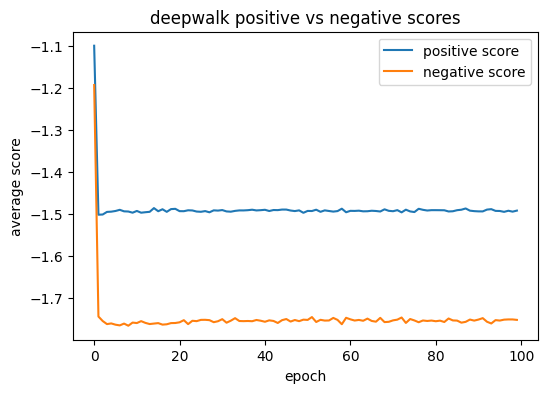

In [65]:
plt.figure(figsize=(6, 4))
plt.plot(deepwalk_history["epoch"], deepwalk_history["average_positive_score"], label="positive score")
plt.plot(deepwalk_history["epoch"], deepwalk_history["average_negative_score"], label="negative score")
plt.xlabel("epoch")
plt.ylabel("average score")
plt.legend()
plt.title("deepwalk positive vs negative scores")
plt.show()

verify that positive scores exceed negative scores after training

In [66]:
assert deepwalk_history["average_positive_score"][-1] > deepwalk_history["average_negative_score"][-1]

extract the learned deepwalk center embeddings

In [67]:
deepwalk_embeddings = deepwalk_model.center_embeddings.weight.detach().numpy()
print("embedding matrix shape", deepwalk_embeddings.shape)
for node in range(num_nodes):
    print(node, deepwalk_embeddings[node])

embedding matrix shape (6, 8)
0 [-1.8384781e-02  5.2981281e-01 -1.4931831e-04 -1.2912265e+00
  3.1277093e-01  4.6084481e-01  1.0417219e+00  6.8428605e-03]
1 [-0.05583027  0.6918376   0.05723154 -0.4464264  -0.15551034 -0.63652176
  0.06060436  0.18825302]
2 [ 2.1263829e-02  1.1039457e+00 -6.2865689e-03  8.0083895e-01
 -6.7105377e-04  2.1774164e-01  4.9987018e-01 -6.3650914e-02]
3 [-0.0075079   0.44327748 -0.03720933  0.11244625 -0.86744434  0.09428364
  0.5351934  -0.04182804]
4 [-0.03503736  0.39551488 -0.01673421 -0.06388542  0.34170723 -0.66308475
  0.63581645  0.02025424]
5 [-0.01713916  1.4626275   0.01876205 -0.04253952 -0.2702083   0.00772171
 -0.33202127  0.05288538]


compute cosine similarity between all pairs of node embeddings

In [68]:
def cosine_similarity_matrix(embeddings):
    norms = np.linalg.norm(embeddings, axis=1, keepdims=True)
    normalized = embeddings / norms
    similarity = normalized @ normalized.T
    return similarity

print the full deepwalk cosine similarity matrix

In [69]:
deepwalk_similarity = cosine_similarity_matrix(deepwalk_embeddings)
deepwalk_similarity

array([[0.99999994, 0.33944824, 0.06354748, 0.20421101, 0.3903517 ,
        0.14469637],
       [0.33944824, 1.0000001 , 0.1802211 , 0.29388887, 0.62786514,
        0.6469911 ],
       [0.06354748, 0.1802211 , 1.0000001 , 0.5275826 , 0.35729772,
        0.62971014],
       [0.20421101, 0.29388887, 0.5275826 , 1.0000001 , 0.1256939 ,
        0.40766537],
       [0.3903517 , 0.62786514, 0.35729772, 0.1256939 , 1.        ,
        0.16946188],
       [0.14469637, 0.6469911 , 0.62971014, 0.40766537, 0.16946188,
        1.        ]], dtype=float32)

verify that the similarity matrix is symmetric

In [70]:
assert np.allclose(deepwalk_similarity, deepwalk_similarity.T)

compute nearest neighbors for a node based on embedding similarity

In [71]:
def nearest_neighbors(similarity_matrix, node, top_k):
    similarities = similarity_matrix[node].copy()
    similarities[node] = -np.inf
    top_indices = np.argsort(-similarities)[:top_k]
    return top_indices.tolist()

print nearest neighbors for every node

In [72]:
for node in range(num_nodes):
    print(node, nearest_neighbors(deepwalk_similarity, node, top_k=3))

0 [4, 1, 3]
1 [5, 4, 0]
2 [5, 3, 4]
3 [2, 5, 1]
4 [1, 0, 2]
5 [1, 2, 3]


implement precision at k using the graph adjacency as ground truth

In [73]:
def precision_at_k(similarity_matrix, A, k):
    num_nodes = A.shape[0]
    precisions = []
    for node in range(num_nodes):
        predicted_neighbors = nearest_neighbors(similarity_matrix, node, k)
        true_neighbors = set(np.where(A[node] == 1)[0].tolist())
        if len(true_neighbors) == 0:
            continue
        num_correct = sum(1 for predicted in predicted_neighbors if predicted in true_neighbors)
        precisions.append(num_correct / k)
    return float(np.mean(precisions))

calculate precision at 1 precision at 2 and precision at 3 for the deepwalk embeddings

In [74]:
deepwalk_precision_at_1 = precision_at_k(deepwalk_similarity, A, 1)
deepwalk_precision_at_2 = precision_at_k(deepwalk_similarity, A, 2)
deepwalk_precision_at_3 = precision_at_k(deepwalk_similarity, A, 3)
deepwalk_precision_at_1, deepwalk_precision_at_2, deepwalk_precision_at_3

(0.6666666666666666, 0.8333333333333334, 0.7222222222222222)

deepwalk captures random walk proximity rather than simply reconstructing direct adjacency

implement a helper that runs a full deepwalk experiment for one configuration

In [75]:
def run_deepwalk_experiment(P, A, num_nodes, embedding_dim, num_walks, walk_length, window_size, num_negative_samples, learning_rate, epochs, batch_size):
    np.random.seed(SEED)
    torch.manual_seed(SEED)
    walks, pairs = generate_deepwalk_pairs(P, num_nodes, num_walks, walk_length, window_size)
    model, history = train_deepwalk(pairs, num_nodes, embedding_dim, num_negative_samples, learning_rate, epochs, batch_size)
    embeddings = model.center_embeddings.weight.detach().numpy()
    similarity = cosine_similarity_matrix(embeddings)
    final_loss = history["average_loss"][-1]
    precision_1 = precision_at_k(similarity, A, 1)
    precision_2 = precision_at_k(similarity, A, 2)
    precision_3 = precision_at_k(similarity, A, 3)
    return final_loss, precision_1, precision_2, precision_3

define the baseline configuration and the parameter grid for deepwalk experiments

In [76]:
deepwalk_baseline_params = {
    "embedding_dim": embedding_dim,
    "num_walks": num_walks,
    "walk_length": walk_length,
    "window_size": window_size,
    "num_negative_samples": num_negative_samples,
    "learning_rate": learning_rate,
    "epochs": 30,
    "batch_size": batch_size
}
deepwalk_experiment_grid = {
    "window_size": [1, 2, 3],
    "walk_length": [5, 10, 20],
    "num_walks": [5, 10, 20],
    "embedding_dim": [2, 4, 8],
    "num_negative_samples": [1, 5, 10]
}

run the deepwalk experiments by changing exactly one parameter at a time

In [77]:
deepwalk_experiment_records = []
for parameter_name, parameter_values in deepwalk_experiment_grid.items():
    for value in parameter_values:
        current_params = dict(deepwalk_baseline_params)
        current_params[parameter_name] = value
        final_loss, precision_1, precision_2, precision_3 = run_deepwalk_experiment(
            P, A, num_nodes,
            current_params["embedding_dim"],
            current_params["num_walks"],
            current_params["walk_length"],
            current_params["window_size"],
            current_params["num_negative_samples"],
            current_params["learning_rate"],
            current_params["epochs"],
            current_params["batch_size"]
        )
        deepwalk_experiment_records.append({
            "parameter": parameter_name,
            "value": value,
            "final_loss": final_loss,
            "precision_at_1": precision_1,
            "precision_at_2": precision_2,
            "precision_at_3": precision_3
        })

collect the deepwalk experiment results into a dataframe

In [78]:
deepwalk_experiment_df = pd.DataFrame(deepwalk_experiment_records)
deepwalk_experiment_df

,parameter,value,final_loss,precision_at_1,precision_at_2,precision_at_3
0,window_size,1,2.073485,0.000000,0.416667,0.555556
1,window_size,2,2.619248,0.500000,0.583333,0.722222
2,window_size,3,2.633185,0.666667,0.583333,0.722222
3,walk_length,5,2.595072,0.833333,0.666667,0.666667
4,walk_length,10,2.620470,0.666667,0.666667,0.611111
5,walk_length,20,2.619248,0.500000,0.583333,0.722222
6,num_walks,5,2.634835,0.666667,0.666667,0.611111
7,num_walks,10,2.626644,0.833333,0.666667,0.611111
8,num_walks,20,2.619248,0.500000,0.583333,0.722222
9,embedding_dim,2,2.643674,1.000000,1.000000,0.888889


deepwalk uses an unbiased random walk where p equals q equals one

node2vec introduces two parameters p and q that bias the random walk

p controls return behavior and q controls bfs versus dfs style exploration

implement the unnormalized node2vec transition weight based on the previous node

In [79]:
def node2vec_bias(previous_node, current_node, next_node, p, q, A):
    if next_node == previous_node:
        return 1.0 / p
    if A[previous_node, next_node] == 1:
        return 1.0
    return 1.0 / q

compute normalized node2vec transition probabilities over the neighbors of the current node

In [80]:
def node2vec_transition(previous_node, current_node, A, p, q):
    neighbors = np.where(A[current_node] == 1)[0]
    weights = np.array([node2vec_bias(previous_node, current_node, neighbor, p, q, A) for neighbor in neighbors])
    probabilities = weights / weights.sum()
    return neighbors, probabilities

print a concrete node2vec transition example from the fixed graph

In [81]:
example_previous_node = 0
example_current_node = 1
example_p = 0.5
example_q = 2.0
example_neighbors, example_probabilities = node2vec_transition(example_previous_node, example_current_node, A, example_p, example_q)
list(zip(example_neighbors.tolist(), example_probabilities.tolist()))

[(0, 0.5), (2, 0.125), (3, 0.125), (4, 0.25)]

implement the node2vec random walk handling the first step separately since it has no previous node

In [82]:
def node2vec_walk(start_node, walk_length, A, p, q):
    walk = [start_node]
    for step in range(walk_length - 1):
        current_node = walk[-1]
        neighbors = np.where(A[current_node] == 1)[0]
        if len(neighbors) == 0:
            break
        if len(walk) == 1:
            next_node = np.random.choice(neighbors)
        else:
            previous_node = walk[-2]
            candidate_neighbors, probabilities = node2vec_transition(previous_node, current_node, A, p, q)
            next_node = np.random.choice(candidate_neighbors, p=probabilities)
        walk.append(next_node)
    return walk

generate an example node2vec walk with balanced return and exploration

In [83]:
node2vec_walk(0, 10, A, p=1, q=1)

[0,
 np.int64(1),
 np.int64(0),
 np.int64(4),
 np.int64(3),
 np.int64(1),
 np.int64(3),
 np.int64(5),
 np.int64(2),
 np.int64(5)]

generate an example node2vec walk favoring breadth first style exploration

In [84]:
node2vec_walk(0, 10, A, p=0.5, q=2)

[0,
 np.int64(4),
 np.int64(3),
 np.int64(4),
 np.int64(5),
 np.int64(4),
 np.int64(5),
 np.int64(4),
 np.int64(5),
 np.int64(3)]

generate an example node2vec walk favoring depth first style exploration

In [85]:
node2vec_walk(0, 10, A, p=2, q=0.5)

[0,
 np.int64(1),
 np.int64(2),
 np.int64(3),
 np.int64(4),
 np.int64(0),
 np.int64(4),
 np.int64(5),
 np.int64(4),
 np.int64(0)]

compare walks generated with different p and q settings from the same start node

In [86]:
np.random.seed(SEED)
comparison_walks = {
    "p=1_q=1": node2vec_walk(0, 15, A, p=1, q=1),
    "p=0.5_q=2": node2vec_walk(0, 15, A, p=0.5, q=2),
    "p=2_q=0.5": node2vec_walk(0, 15, A, p=2, q=0.5)
}
comparison_walks

{'p=1_q=1': [0,
  np.int64(1),
  np.int64(4),
  np.int64(0),
  np.int64(4),
  np.int64(3),
  np.int64(2),
  np.int64(1),
  np.int64(2),
  np.int64(3),
  np.int64(1),
  np.int64(3),
  np.int64(1),
  np.int64(3),
  np.int64(5)],
 'p=0.5_q=2': [0,
  np.int64(4),
  np.int64(0),
  np.int64(1),
  np.int64(0),
  np.int64(1),
  np.int64(0),
  np.int64(1),
  np.int64(2),
  np.int64(1),
  np.int64(2),
  np.int64(1),
  np.int64(2),
  np.int64(3),
  np.int64(1)],
 'p=2_q=0.5': [0,
  np.int64(1),
  np.int64(4),
  np.int64(3),
  np.int64(5),
  np.int64(4),
  np.int64(1),
  np.int64(0),
  np.int64(4),
  np.int64(3),
  np.int64(2),
  np.int64(1),
  np.int64(0),
  np.int64(1),
  np.int64(3)]}

generate node2vec walks and context pairs for a given p and q

In [87]:
def generate_node2vec_pairs(A, num_nodes, num_walks, walk_length, window_size, p, q):
    walks = []
    for _ in range(num_walks):
        for start_node in range(num_nodes):
            walks.append(node2vec_walk(start_node, walk_length, A, p, q))
    pairs = generate_pairs_from_walks(walks, window_size)
    return walks, pairs

train node2vec by reusing the same skip-gram model and training loop as deepwalk

In [88]:
def train_node2vec(A, num_nodes, num_walks, walk_length, window_size, p, q, embedding_dim, num_negative_samples, learning_rate, epochs, batch_size):
    walks, pairs = generate_node2vec_pairs(A, num_nodes, num_walks, walk_length, window_size, p, q)
    model, history = train_deepwalk(pairs, num_nodes, embedding_dim, num_negative_samples, learning_rate, epochs, batch_size)
    return model, history, walks, pairs

reset the seeds and train node2vec with balanced return and exploration parameters

In [89]:
np.random.seed(SEED)
torch.manual_seed(SEED)
node2vec_model_balanced, node2vec_history_balanced, node2vec_walks_balanced, node2vec_pairs_balanced = train_node2vec(
    A, num_nodes, num_walks, walk_length, window_size, p=1, q=1,
    embedding_dim=embedding_dim, num_negative_samples=num_negative_samples,
    learning_rate=learning_rate, epochs=epochs, batch_size=batch_size
)

reset the seeds and train node2vec with breadth first and depth first biased parameters

In [90]:
np.random.seed(SEED)
torch.manual_seed(SEED)
node2vec_model_bfs, node2vec_history_bfs, node2vec_walks_bfs, node2vec_pairs_bfs = train_node2vec(
    A, num_nodes, num_walks, walk_length, window_size, p=0.5, q=2,
    embedding_dim=embedding_dim, num_negative_samples=num_negative_samples,
    learning_rate=learning_rate, epochs=epochs, batch_size=batch_size
)
np.random.seed(SEED)
torch.manual_seed(SEED)
node2vec_model_dfs, node2vec_history_dfs, node2vec_walks_dfs, node2vec_pairs_dfs = train_node2vec(
    A, num_nodes, num_walks, walk_length, window_size, p=2, q=0.5,
    embedding_dim=embedding_dim, num_negative_samples=num_negative_samples,
    learning_rate=learning_rate, epochs=epochs, batch_size=batch_size
)

extract embeddings and similarity matrices for every trained node2vec model

In [91]:
node2vec_embeddings_balanced = node2vec_model_balanced.center_embeddings.weight.detach().numpy()
node2vec_embeddings_bfs = node2vec_model_bfs.center_embeddings.weight.detach().numpy()
node2vec_embeddings_dfs = node2vec_model_dfs.center_embeddings.weight.detach().numpy()
node2vec_similarity_balanced = cosine_similarity_matrix(node2vec_embeddings_balanced)
node2vec_similarity_bfs = cosine_similarity_matrix(node2vec_embeddings_bfs)
node2vec_similarity_dfs = cosine_similarity_matrix(node2vec_embeddings_dfs)

compute final loss and precision at k for deepwalk and every node2vec variant

In [92]:
comparison_records = []
for method_name, similarity_matrix, history in [
    ("deepwalk", deepwalk_similarity, deepwalk_history),
    ("node2vec p=1 q=1", node2vec_similarity_balanced, node2vec_history_balanced),
    ("node2vec bfs-like", node2vec_similarity_bfs, node2vec_history_bfs),
    ("node2vec dfs-like", node2vec_similarity_dfs, node2vec_history_dfs)
]:
    comparison_records.append({
        "method": method_name,
        "final_loss": history["average_loss"][-1],
        "precision_at_1": precision_at_k(similarity_matrix, A, 1),
        "precision_at_2": precision_at_k(similarity_matrix, A, 2),
        "precision_at_3": precision_at_k(similarity_matrix, A, 3)
    })
comparison_df = pd.DataFrame(comparison_records)
comparison_df

,method,final_loss,precision_at_1,precision_at_2,precision_at_3
0,deepwalk,2.609926,0.666667,0.833333,0.722222
1,node2vec p=1 q=1,2.626781,0.833333,0.916667,0.722222
2,node2vec bfs-like,2.551044,1.000000,1.000000,0.944444
3,node2vec dfs-like,2.618286,0.166667,0.416667,0.500000


print nearest neighbors for every node under every method

In [93]:
for method_name, similarity_matrix in [
    ("deepwalk", deepwalk_similarity),
    ("node2vec p=1 q=1", node2vec_similarity_balanced),
    ("node2vec bfs-like", node2vec_similarity_bfs),
    ("node2vec dfs-like", node2vec_similarity_dfs)
]:
    print(method_name)
    for node in range(num_nodes):
        print(node, nearest_neighbors(similarity_matrix, node, top_k=2))

deepwalk
0 [4, 1]
1 [5, 4]
2 [5, 3]
3 [2, 5]
4 [1, 0]
5 [1, 2]
node2vec p=1 q=1
0 [4, 1]
1 [5, 4]
2 [5, 3]
3 [5, 2]
4 [0, 1]
5 [2, 3]
node2vec bfs-like
0 [1, 4]
1 [0, 3]
2 [3, 1]
3 [2, 5]
4 [0, 3]
5 [3, 2]
node2vec dfs-like
0 [5, 2]
1 [5, 3]
2 [0, 4]
3 [0, 4]
4 [5, 3]
5 [0, 4]


reduce embeddings to two dimensions using pca for visualization

In [94]:
def reduce_to_2d(embeddings):
    pca = PCA(n_components=2, random_state=SEED)
    return pca.fit_transform(embeddings)

visualize deepwalk and node2vec embeddings side by side using pca

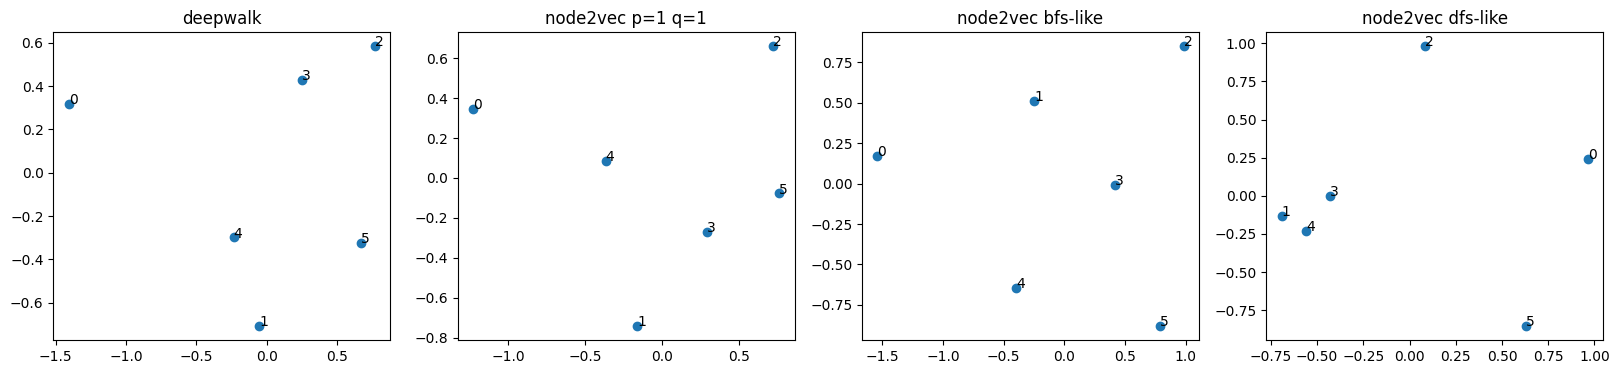

In [95]:
fig, axes = plt.subplots(1, 4, figsize=(20, 4))
embedding_sets = [
    ("deepwalk", deepwalk_embeddings),
    ("node2vec p=1 q=1", node2vec_embeddings_balanced),
    ("node2vec bfs-like", node2vec_embeddings_bfs),
    ("node2vec dfs-like", node2vec_embeddings_dfs)
]
for ax, (method_name, embeddings) in zip(axes, embedding_sets):
    reduced = reduce_to_2d(embeddings)
    ax.scatter(reduced[:, 0], reduced[:, 1])
    for node in range(num_nodes):
        ax.annotate(str(node), (reduced[node, 0], reduced[node, 1]))
    ax.set_title(method_name)
plt.show()

interpret these results relative to this specific graph rather than as a universal claim

build the final comparison table across methods and hyperparameters

In [96]:
final_comparison_records = [
    {
        "method": "deepwalk", "p": None, "q": None,
        "embedding_dim": embedding_dim, "num_walks": num_walks, "walk_length": walk_length,
        "window_size": window_size, "num_negative_samples": num_negative_samples,
        "final_loss": deepwalk_history["average_loss"][-1],
        "precision_at_1": precision_at_k(deepwalk_similarity, A, 1),
        "precision_at_2": precision_at_k(deepwalk_similarity, A, 2),
        "precision_at_3": precision_at_k(deepwalk_similarity, A, 3)
    },
    {
        "method": "node2vec p=1 q=1", "p": 1, "q": 1,
        "embedding_dim": embedding_dim, "num_walks": num_walks, "walk_length": walk_length,
        "window_size": window_size, "num_negative_samples": num_negative_samples,
        "final_loss": node2vec_history_balanced["average_loss"][-1],
        "precision_at_1": precision_at_k(node2vec_similarity_balanced, A, 1),
        "precision_at_2": precision_at_k(node2vec_similarity_balanced, A, 2),
        "precision_at_3": precision_at_k(node2vec_similarity_balanced, A, 3)
    },
    {
        "method": "node2vec bfs-like", "p": 0.5, "q": 2,
        "embedding_dim": embedding_dim, "num_walks": num_walks, "walk_length": walk_length,
        "window_size": window_size, "num_negative_samples": num_negative_samples,
        "final_loss": node2vec_history_bfs["average_loss"][-1],
        "precision_at_1": precision_at_k(node2vec_similarity_bfs, A, 1),
        "precision_at_2": precision_at_k(node2vec_similarity_bfs, A, 2),
        "precision_at_3": precision_at_k(node2vec_similarity_bfs, A, 3)
    },
    {
        "method": "node2vec dfs-like", "p": 2, "q": 0.5,
        "embedding_dim": embedding_dim, "num_walks": num_walks, "walk_length": walk_length,
        "window_size": window_size, "num_negative_samples": num_negative_samples,
        "final_loss": node2vec_history_dfs["average_loss"][-1],
        "precision_at_1": precision_at_k(node2vec_similarity_dfs, A, 1),
        "precision_at_2": precision_at_k(node2vec_similarity_dfs, A, 2),
        "precision_at_3": precision_at_k(node2vec_similarity_dfs, A, 3)
    }
]
final_comparison_df = pd.DataFrame(final_comparison_records)
final_comparison_df

,method,p,q,embedding_dim,num_walks,walk_length,window_size,num_negative_samples,final_loss,precision_at_1,precision_at_2,precision_at_3
0,deepwalk,NaN,NaN,8,20,20,2,5,2.609926,0.666667,0.833333,0.722222
1,node2vec p=1 q=1,1.0,1.0,8,20,20,2,5,2.626781,0.833333,0.916667,0.722222
2,node2vec bfs-like,0.5,2.0,8,20,20,2,5,2.551044,1.000000,1.000000,0.944444
3,node2vec dfs-like,2.0,0.5,8,20,20,2,5,2.618286,0.166667,0.416667,0.500000


run final automatic sanity checks across the whole notebook

In [97]:
assert np.allclose(P.sum(axis=1), 1)
assert all(walk_transitions_are_valid(walk, A) for walk in deepwalk_walks)
assert all(walk_transitions_are_valid(walk, A) for walk in node2vec_walks_balanced)
assert all(walk_transitions_are_valid(walk, A) for walk in node2vec_walks_bfs)
assert all(walk_transitions_are_valid(walk, A) for walk in node2vec_walks_dfs)
tiny_pairs_check = generate_context_pairs([0, 1, 2, 3, 4], 2)
assert all(center != context for center, context in tiny_pairs_check)
negative_check = sample_negative_nodes(num_nodes, 1, 5)
assert all(negative != 1 for negative in negative_check)
assert np.isfinite(deepwalk_history["average_loss"][-1])
assert np.isfinite(node2vec_history_balanced["average_loss"][-1])
assert torch.isfinite(center_grad).all()
assert torch.isfinite(context_grad).all()
assert deepwalk_embeddings.shape == (num_nodes, embedding_dim)
assert np.allclose(deepwalk_similarity, deepwalk_similarity.T)
print("all sanity checks passed")

all sanity checks passed


the same seed and the same fixed graph were used throughout for reproducible comparisons

apply the exact same deepwalk and node2vec functions defined above to a real world graph

zachary karate club is a real social network of 34 members with 78 observed friendships

define the zachary karate club edge list

In [98]:
karate_club_edges = [
    (0,1),(0,2),(0,3),(0,4),(0,5),(0,6),(0,7),(0,8),(0,10),(0,11),(0,12),(0,13),(0,17),(0,19),(0,21),(0,31),
    (1,2),(1,3),(1,7),(1,13),(1,17),(1,19),(1,21),(1,30),
    (2,3),(2,7),(2,8),(2,9),(2,13),(2,27),(2,28),(2,32),
    (3,7),(3,12),(3,13),
    (4,6),(4,10),
    (5,6),(5,10),(5,16),
    (6,16),
    (8,30),(8,32),(8,33),
    (9,33),
    (13,33),
    (14,32),(14,33),
    (15,32),(15,33),
    (18,32),(18,33),
    (19,33),
    (20,32),(20,33),
    (22,32),(22,33),
    (23,25),(23,27),(23,29),(23,32),(23,33),
    (24,25),(24,27),(24,31),
    (25,31),
    (26,29),(26,33),
    (27,33),
    (28,31),(28,33),
    (29,32),(29,33),
    (30,32),(30,33),
    (31,32),(31,33),
    (32,33)
]

build the real world adjacency matrix from the edge list using plain numpy

In [99]:
num_nodes_real = 34
A_real = np.zeros((num_nodes_real, num_nodes_real), dtype=int)
for source_node, target_node in karate_club_edges:
    A_real[source_node, target_node] = 1
    A_real[target_node, source_node] = 1

verify the real world adjacency matrix is symmetric and inspect its degree distribution

In [100]:
assert np.array_equal(A_real, A_real.T)
assert int(A_real.sum() / 2) == len(karate_club_edges)
A_real.sum(axis=1)

array([16,  9, 10,  6,  3,  4,  4,  4,  5,  2,  3,  1,  2,  5,  2,  2,  2,
        2,  2,  3,  2,  2,  2,  5,  3,  3,  2,  4,  3,  4,  4,  6, 12, 17])

reuse the existing transition_matrix function unchanged on the real world graph

In [101]:
P_real = transition_matrix(A_real)
assert np.allclose(P_real.sum(axis=1), 1)
P_real.shape

(34, 34)

reuse the existing deepwalk pair generation and training functions unchanged on the real world graph

In [102]:
np.random.seed(SEED)
torch.manual_seed(SEED)
karate_walks, karate_pairs = generate_deepwalk_pairs(P_real, num_nodes_real, num_walks, walk_length, window_size)
karate_deepwalk_model, karate_deepwalk_history = train_deepwalk(karate_pairs, num_nodes_real, embedding_dim, num_negative_samples, learning_rate, epochs, batch_size)
len(karate_walks), len(karate_pairs)

(680, 50320)

reuse the existing node2vec pair generation and training functions unchanged on the real world graph

In [103]:
np.random.seed(SEED)
torch.manual_seed(SEED)
karate_node2vec_model, karate_node2vec_history, karate_node2vec_walks, karate_node2vec_pairs = train_node2vec(
    A_real, num_nodes_real, num_walks, walk_length, window_size, p=0.5, q=2,
    embedding_dim=embedding_dim, num_negative_samples=num_negative_samples,
    learning_rate=learning_rate, epochs=epochs, batch_size=batch_size
)

extract embeddings and evaluate precision at k using the same functions defined earlier

In [104]:
karate_deepwalk_embeddings = karate_deepwalk_model.center_embeddings.weight.detach().numpy()
karate_node2vec_embeddings = karate_node2vec_model.center_embeddings.weight.detach().numpy()
karate_deepwalk_similarity = cosine_similarity_matrix(karate_deepwalk_embeddings)
karate_node2vec_similarity = cosine_similarity_matrix(karate_node2vec_embeddings)
karate_results = pd.DataFrame([
    {
        "method": "deepwalk on karate club",
        "final_loss": karate_deepwalk_history["average_loss"][-1],
        "precision_at_1": precision_at_k(karate_deepwalk_similarity, A_real, 1),
        "precision_at_2": precision_at_k(karate_deepwalk_similarity, A_real, 2),
        "precision_at_3": precision_at_k(karate_deepwalk_similarity, A_real, 3)
    },
    {
        "method": "node2vec bfs-like on karate club",
        "final_loss": karate_node2vec_history["average_loss"][-1],
        "precision_at_1": precision_at_k(karate_node2vec_similarity, A_real, 1),
        "precision_at_2": precision_at_k(karate_node2vec_similarity, A_real, 2),
        "precision_at_3": precision_at_k(karate_node2vec_similarity, A_real, 3)
    }
])
karate_results

,method,final_loss,precision_at_1,precision_at_2,precision_at_3
0,deepwalk on karate club,1.944864,0.617647,0.573529,0.549020
1,node2vec bfs-like on karate club,1.806501,0.735294,0.691176,0.627451


visualize the real world karate club embeddings using the same pca helper defined earlier

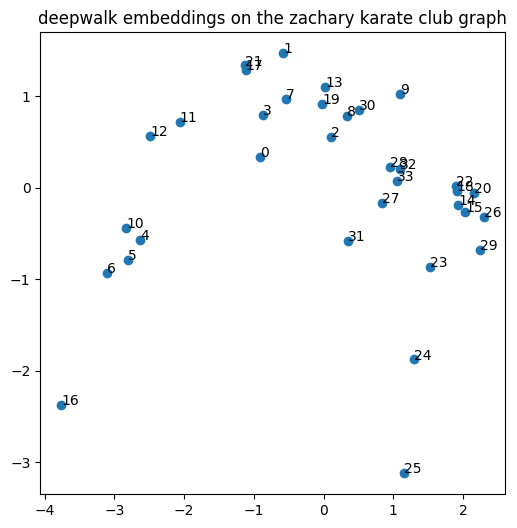

In [105]:
karate_reduced = reduce_to_2d(karate_deepwalk_embeddings)
plt.figure(figsize=(6, 6))
plt.scatter(karate_reduced[:, 0], karate_reduced[:, 1])
for node in range(num_nodes_real):
    plt.annotate(str(node), (karate_reduced[node, 0], karate_reduced[node, 1]))
plt.title("deepwalk embeddings on the zachary karate club graph")
plt.show()

use degree similarity as a simple proxy for structural equivalence between nodes

In [106]:
def structural_similarity_matrix(degree_vector):
    degree_column = degree_vector.reshape(-1, 1)
    degree_row = degree_vector.reshape(1, -1)
    return -np.abs(degree_column - degree_row).astype(float)

collect the indices of node pairs that are not directly connected by an edge

In [107]:
def non_adjacent_pair_indices(A):
    num_nodes = A.shape[0]
    pairs = [(i, j) for i in range(num_nodes) for j in range(i + 1, num_nodes) if A[i, j] == 0]
    return pairs

correlate embedding similarity with structural similarity across non adjacent pairs

In [108]:
def structural_equivalence_correlation(embedding_similarity, structural_similarity, non_adjacent_pairs):
    embedding_values = np.array([embedding_similarity[i, j] for i, j in non_adjacent_pairs])
    structural_values = np.array([structural_similarity[i, j] for i, j in non_adjacent_pairs])
    correlation_matrix = np.corrcoef(embedding_values, structural_values)
    return float(correlation_matrix[0, 1])

compute structural equivalence correlation for every method on the fixed graph

In [109]:
structural_similarity_fixed = structural_similarity_matrix(degree_vector)
non_adjacent_pairs_fixed = non_adjacent_pair_indices(A)
structural_equivalence_records = []
for method_name, similarity_matrix in [
    ("deepwalk", deepwalk_similarity),
    ("node2vec p=1 q=1", node2vec_similarity_balanced),
    ("node2vec bfs-like", node2vec_similarity_bfs),
    ("node2vec dfs-like", node2vec_similarity_dfs)
]:
    correlation = structural_equivalence_correlation(similarity_matrix, structural_similarity_fixed, non_adjacent_pairs_fixed)
    structural_equivalence_records.append({"method": method_name, "structural_equivalence_correlation": correlation})
structural_equivalence_df = pd.DataFrame(structural_equivalence_records)
structural_equivalence_df

,method,structural_equivalence_correlation
0,deepwalk,0.192389
1,node2vec p=1 q=1,0.269412
2,node2vec bfs-like,-0.364926
3,node2vec dfs-like,0.256907


compute the same structural equivalence correlation on the real world karate club graph

In [110]:
karate_degree_vector = A_real.sum(axis=1)
structural_similarity_real = structural_similarity_matrix(karate_degree_vector)
non_adjacent_pairs_real = non_adjacent_pair_indices(A_real)
karate_structural_equivalence_records = []
for method_name, similarity_matrix in [
    ("deepwalk on karate club", karate_deepwalk_similarity),
    ("node2vec bfs-like on karate club", karate_node2vec_similarity)
]:
    correlation = structural_equivalence_correlation(similarity_matrix, structural_similarity_real, non_adjacent_pairs_real)
    karate_structural_equivalence_records.append({"method": method_name, "structural_equivalence_correlation": correlation})
karate_structural_equivalence_df = pd.DataFrame(karate_structural_equivalence_records)
karate_structural_equivalence_df

,method,structural_equivalence_correlation
0,deepwalk on karate club,0.123961
1,node2vec bfs-like on karate club,0.151462


a higher correlation means nodes with similar degree end up closer in embedding space even when they are not connected

repeat the deepwalk versus node2vec comparison across multiple seeds to check how much results depend on one sample of random walks

In [111]:
def run_comparison_trial(seed, P, A, num_nodes, embedding_dim, num_walks, walk_length, window_size, num_negative_samples, learning_rate, epochs, batch_size):
    trial_records = []
    np.random.seed(seed)
    torch.manual_seed(seed)
    trial_deepwalk_walks, trial_deepwalk_pairs = generate_deepwalk_pairs(P, num_nodes, num_walks, walk_length, window_size)
    trial_deepwalk_model, trial_deepwalk_history = train_deepwalk(trial_deepwalk_pairs, num_nodes, embedding_dim, num_negative_samples, learning_rate, epochs, batch_size)
    trial_deepwalk_embeddings = trial_deepwalk_model.center_embeddings.weight.detach().numpy()
    trial_deepwalk_similarity = cosine_similarity_matrix(trial_deepwalk_embeddings)
    trial_records.append({
        "seed": seed,
        "method": "deepwalk",
        "final_loss": trial_deepwalk_history["average_loss"][-1],
        "precision_at_1": precision_at_k(trial_deepwalk_similarity, A, 1),
        "precision_at_2": precision_at_k(trial_deepwalk_similarity, A, 2),
        "precision_at_3": precision_at_k(trial_deepwalk_similarity, A, 3)
    })
    for method_name, p_value, q_value in [("node2vec p=1 q=1", 1, 1), ("node2vec bfs-like", 0.5, 2), ("node2vec dfs-like", 2, 0.5)]:
        np.random.seed(seed)
        torch.manual_seed(seed)
        trial_model, trial_history, trial_walks, trial_pairs = train_node2vec(A, num_nodes, num_walks, walk_length, window_size, p_value, q_value, embedding_dim, num_negative_samples, learning_rate, epochs, batch_size)
        trial_embeddings = trial_model.center_embeddings.weight.detach().numpy()
        trial_similarity = cosine_similarity_matrix(trial_embeddings)
        trial_records.append({
            "seed": seed,
            "method": method_name,
            "final_loss": trial_history["average_loss"][-1],
            "precision_at_1": precision_at_k(trial_similarity, A, 1),
            "precision_at_2": precision_at_k(trial_similarity, A, 2),
            "precision_at_3": precision_at_k(trial_similarity, A, 3)
        })
    return trial_records

run the trial across five different seeds using fewer epochs to keep runtime reasonable

In [112]:
trial_epochs = 40
trial_seeds = [0, 1, 2, 3, 4]
multi_seed_records = []
for trial_seed in trial_seeds:
    multi_seed_records.extend(run_comparison_trial(trial_seed, P, A, num_nodes, embedding_dim, num_walks, walk_length, window_size, num_negative_samples, learning_rate, trial_epochs, batch_size))

collect the multi seed results into a dataframe

In [113]:
multi_seed_df = pd.DataFrame(multi_seed_records)
multi_seed_df

,seed,method,final_loss,precision_at_1,precision_at_2,precision_at_3
0,0,deepwalk,2.618832,0.833333,0.583333,0.555556
1,0,node2vec p=1 q=1,2.614827,0.500000,0.583333,0.555556
2,0,node2vec bfs-like,2.538028,1.000000,0.833333,0.777778
3,0,node2vec dfs-like,2.617003,0.500000,0.500000,0.444444
4,1,deepwalk,2.609836,1.000000,0.916667,0.722222
5,1,node2vec p=1 q=1,2.619976,1.000000,0.916667,0.722222
6,1,node2vec bfs-like,2.537182,1.000000,1.000000,0.944444
7,1,node2vec dfs-like,2.617299,0.500000,0.666667,0.666667
8,2,deepwalk,2.618161,0.666667,0.666667,0.722222
9,2,node2vec p=1 q=1,2.612870,0.666667,0.750000,0.722222


summarize each method as a mean and standard deviation across the five seeds

In [114]:
multi_seed_summary = multi_seed_df.groupby("method")[["final_loss", "precision_at_1", "precision_at_2", "precision_at_3"]].agg(["mean", "std"])
multi_seed_summary

final_loss           precision_at_1            \
                        mean       std           mean       std   
method                                                            
deepwalk            2.612937  0.005838       0.766667  0.278887   
node2vec bfs-like   2.535898  0.008348       1.000000  0.000000   
node2vec dfs-like   2.616257  0.002889       0.466667  0.074536   
node2vec p=1 q=1    2.615681  0.002907       0.766667  0.223607   

                  precision_at_2           precision_at_3            
                            mean       std           mean       std  
method                                                               
deepwalk                0.716667  0.151383       0.688889  0.074536  
node2vec bfs-like       0.966667  0.074536       0.900000  0.072436  
node2vec dfs-like       0.533333  0.074536       0.555556  0.087841  
node2vec p=1 q=1        0.766667  0.123603       0.688889  0.074536

visualize the spread of precision at 1 across seeds for every method

/tmp/ipykernel_26979/437255320.py:4: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(grouped_precision, labels=method_order)


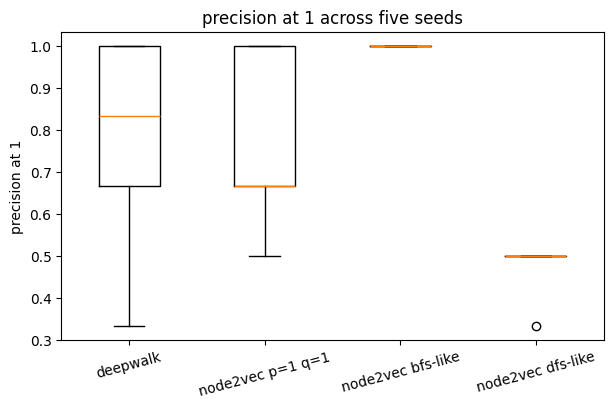

In [115]:
plt.figure(figsize=(7, 4))
method_order = ["deepwalk", "node2vec p=1 q=1", "node2vec bfs-like", "node2vec dfs-like"]
grouped_precision = [multi_seed_df[multi_seed_df["method"] == method_name]["precision_at_1"].values for method_name in method_order]
plt.boxplot(grouped_precision, labels=method_order)
plt.ylabel("precision at 1")
plt.title("precision at 1 across five seeds")
plt.xticks(rotation=15)
plt.show()

verify that the multi seed summary is finite and has one row per method

In [116]:
assert multi_seed_summary.shape[0] == 4
assert np.isfinite(multi_seed_df["final_loss"]).all()
assert np.isfinite(multi_seed_df["precision_at_1"]).all()

the original deepwalk paper does not use negative sampling, it uses hierarchical softmax

hierarchical softmax replaces one flat softmax over all nodes with a binary tree of small decisions

assign every node a binary code by recursively splitting the node list into two halves, one bit per split

In [117]:
def assign_binary_codes(num_nodes):
    node_ids = list(range(num_nodes))
    codes = [None] * num_nodes
    def split_into_codes(ids, prefix):
        if len(ids) == 1:
            codes[ids[0]] = prefix
            return
        midpoint = len(ids) // 2
        split_into_codes(ids[:midpoint], prefix + "0")
        split_into_codes(ids[midpoint:], prefix + "1")
    split_into_codes(node_ids, "")
    return codes

build one parameter vector for every internal tree node that actually appears along some path

In [118]:
def build_internal_node_vectors(codes, embedding_dim):
    internal_node_vectors = {}
    for code_string in codes:
        prefix = ""
        for bit in code_string:
            if prefix not in internal_node_vectors:
                internal_node_vectors[prefix] = np.random.normal(size=embedding_dim)
            prefix += bit
    return internal_node_vectors

compute the probability of one target node as a product of sigmoids along its tree path

In [119]:
def hierarchical_softmax_probability(center_vector, code_string, internal_node_vectors):
    probability = 1.0
    prefix = ""
    for bit in code_string:
        internal_vector = internal_node_vectors[prefix]
        sign = 1.0 if bit == "0" else -1.0
        probability *= sigmoid(sign * dot_score(center_vector, internal_vector))
        prefix += bit
    return probability

verify hierarchical softmax is a valid probability distribution over the fixed graph nodes

In [120]:
hierarchical_codes = assign_binary_codes(num_nodes)
hierarchical_internal_vectors = build_internal_node_vectors(hierarchical_codes, embedding_dim_demo)
hierarchical_center_vector = np.random.normal(size=embedding_dim_demo)
hierarchical_probabilities = [hierarchical_softmax_probability(hierarchical_center_vector, code_string, hierarchical_internal_vectors) for code_string in hierarchical_codes]
print("code lengths used", sorted(set(len(c) for c in hierarchical_codes)), "instead of a flat softmax over", num_nodes, "nodes")
print("per node probabilities", hierarchical_probabilities)
print("sum of probabilities", sum(hierarchical_probabilities))
assert np.isclose(sum(hierarchical_probabilities), 1.0)

code lengths used [2, 3] instead of a flat softmax over 6 nodes
per node probabilities [np.float64(0.08077030364605411), np.float64(0.028522272541515455), np.float64(0.0235103299652881), np.float64(0.29358779675063784), np.float64(0.20471120969119816), np.float64(0.36889808740530616)]
sum of probabilities 0.9999999999999999


node2vec keeps negative sampling but makes walk simulation fast with alias sampling instead of rebuilding a cumulative distribution at every step

build an alias table so that any single sample from a fixed distribution costs constant time

In [121]:
def build_alias_table(probabilities):
    num_outcomes = len(probabilities)
    scaled_probabilities = np.array(probabilities, dtype=float) * num_outcomes
    probability_table = np.zeros(num_outcomes)
    alias_table = np.zeros(num_outcomes, dtype=int)
    small_outcomes = [i for i in range(num_outcomes) if scaled_probabilities[i] < 1.0]
    large_outcomes = [i for i in range(num_outcomes) if scaled_probabilities[i] >= 1.0]
    while small_outcomes and large_outcomes:
        small_index = small_outcomes.pop()
        large_index = large_outcomes.pop()
        probability_table[small_index] = scaled_probabilities[small_index]
        alias_table[small_index] = large_index
        scaled_probabilities[large_index] = scaled_probabilities[large_index] - (1.0 - scaled_probabilities[small_index])
        if scaled_probabilities[large_index] < 1.0:
            small_outcomes.append(large_index)
        else:
            large_outcomes.append(large_index)
    for remaining_index in small_outcomes + large_outcomes:
        probability_table[remaining_index] = 1.0
    return probability_table, alias_table

draw one sample from the alias table in constant time regardless of how many outcomes exist

In [122]:
def alias_sample(probability_table, alias_table):
    num_outcomes = len(probability_table)
    column = np.random.randint(num_outcomes)
    coin_flip = np.random.rand() < probability_table[column]
    return column if coin_flip else alias_table[column]

verify alias sampling reproduces the true node2vec transition probabilities on the fixed graph

In [123]:
alias_demo_neighbors, alias_demo_probabilities = node2vec_transition(0, 1, A, p=0.5, q=2)
alias_probability_table, alias_table = build_alias_table(alias_demo_probabilities)
alias_draws = [alias_demo_neighbors[alias_sample(alias_probability_table, alias_table)] for _ in range(20000)]
alias_empirical = np.array([np.mean(np.array(alias_draws) == neighbor) for neighbor in alias_demo_neighbors])
print("true probabilities", alias_demo_probabilities)
print("alias sampled empirical frequencies", alias_empirical)
assert np.max(np.abs(alias_empirical - alias_demo_probabilities)) < 0.02

true probabilities [0.5   0.125 0.125 0.25 ]
alias sampled empirical frequencies [0.4942  0.12265 0.1284  0.25475]


apply the paper accurate implementation to a real dataset used in the node2vec paper itself

the homo sapiens protein interaction network has 3890 nodes 50 gene ontology labels and is downloaded directly from the node2vec authors

load the real dataset from a local copy or download it once if missing

In [124]:
import os
import urllib.request
import scipy.io

real_dataset_path = "Homo_sapiens.mat"
real_dataset_url = "https://snap.stanford.edu/node2vec/Homo_sapiens.mat"
if not os.path.exists(real_dataset_path):
    urllib.request.urlretrieve(real_dataset_url, real_dataset_path)
real_dataset = scipy.io.loadmat(real_dataset_path)

build the dense adjacency matrix and the multi label matrix from the loaded dataset

In [125]:
A_ppi = np.asarray(real_dataset["network"].todense())
labels_ppi = np.asarray(real_dataset["group"].todense())
num_nodes_ppi = A_ppi.shape[0]
num_nodes_ppi, A_ppi.sum() / 2, labels_ppi.shape[1]

(3890, np.float64(38292.0), 50)

verify the real dataset matches the statistics reported in the node2vec paper

In [126]:
assert num_nodes_ppi == 3890
assert labels_ppi.shape[1] == 50
assert np.array_equal(A_ppi, A_ppi.T)
assert (A_ppi.sum(axis=1) == 0).sum() == 0

reuse the existing transition_matrix function unchanged on the real dataset

In [127]:
P_ppi = transition_matrix(A_ppi)
assert np.allclose(P_ppi.sum(axis=1), 1)

negative sampling as a per pair python loop is too slow at this scale so vectorize it with numpy

In [128]:
def sample_negative_nodes_batch(num_nodes, positive_nodes, num_negative_samples):
    batch_size = positive_nodes.shape[0]
    negative_nodes = np.random.randint(0, num_nodes, size=(batch_size, num_negative_samples))
    colliding = negative_nodes == positive_nodes.reshape(-1, 1)
    while colliding.any():
        negative_nodes[colliding] = np.random.randint(0, num_nodes, size=int(colliding.sum()))
        colliding = negative_nodes == positive_nodes.reshape(-1, 1)
    return negative_nodes

reuse the same skipgram architecture and loss but swap in the vectorized negative sampler for a scalable training loop

In [129]:
def train_skipgram_scalable(pairs, num_nodes, embedding_dim, num_negative_samples, learning_rate, epochs, batch_size):
    model = SkipGram(num_nodes, embedding_dim)
    optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)
    pairs_array = np.array(pairs)
    history = {"epoch": [], "average_loss": []}
    for epoch in range(epochs):
        permutation = np.random.permutation(len(pairs_array))
        shuffled_pairs = pairs_array[permutation]
        epoch_losses = []
        for start in range(0, len(shuffled_pairs), batch_size):
            batch = shuffled_pairs[start:start + batch_size]
            center_nodes = torch.tensor(batch[:, 0], dtype=torch.long)
            positive_nodes_np = batch[:, 1]
            positive_nodes = torch.tensor(positive_nodes_np, dtype=torch.long)
            negative_nodes_np = sample_negative_nodes_batch(num_nodes, positive_nodes_np, num_negative_samples)
            negative_nodes = torch.tensor(negative_nodes_np, dtype=torch.long)
            optimizer.zero_grad()
            loss = model(center_nodes, positive_nodes, negative_nodes)
            loss.backward()
            optimizer.step()
            epoch_losses.append(loss.item())
        history["epoch"].append(epoch)
        history["average_loss"].append(float(np.mean(epoch_losses)))
    return model, history

define reduced but still meaningful hyperparameters so training finishes quickly on a laptop

In [130]:
ppi_embedding_dim = 64
ppi_num_walks = 5
ppi_walk_length = 10
ppi_window_size = 2
ppi_num_negative_samples = 5
ppi_learning_rate = 0.01
ppi_epochs = 15
ppi_batch_size = 512

the original papers use much larger walks such as length 80 and 10 walks per node with 128 dimensions which is not tractable with a pure python from scratch sampler on a laptop

reuse the existing deepwalk pair generation and the new scalable trainer on the real dataset

In [131]:
np.random.seed(SEED)
torch.manual_seed(SEED)
ppi_deepwalk_walks, ppi_deepwalk_pairs = generate_deepwalk_pairs(P_ppi, num_nodes_ppi, ppi_num_walks, ppi_walk_length, ppi_window_size)
ppi_deepwalk_model, ppi_deepwalk_history = train_skipgram_scalable(ppi_deepwalk_pairs, num_nodes_ppi, ppi_embedding_dim, ppi_num_negative_samples, ppi_learning_rate, ppi_epochs, ppi_batch_size)
len(ppi_deepwalk_walks), len(ppi_deepwalk_pairs)

(19450, 661300)

reuse the existing node2vec pair generation and the same scalable trainer with a bfs like bias

In [132]:
def generate_node2vec_pairs_scalable(A, num_nodes, num_walks, walk_length, window_size, p, q):
    walks = []
    for _ in range(num_walks):
        for start_node in range(num_nodes):
            walks.append(node2vec_walk(start_node, walk_length, A, p, q))
    pairs = generate_pairs_from_walks(walks, window_size)
    return walks, pairs

train node2vec on the real dataset with a moderate return and exploration bias

In [133]:
np.random.seed(SEED)
torch.manual_seed(SEED)
ppi_node2vec_walks, ppi_node2vec_pairs = generate_node2vec_pairs_scalable(A_ppi, num_nodes_ppi, ppi_num_walks, ppi_walk_length, ppi_window_size, p=1, q=2)
ppi_node2vec_model, ppi_node2vec_history = train_skipgram_scalable(ppi_node2vec_pairs, num_nodes_ppi, ppi_embedding_dim, ppi_num_negative_samples, ppi_learning_rate, ppi_epochs, ppi_batch_size)
len(ppi_node2vec_walks), len(ppi_node2vec_pairs)

(19450, 661300)

plot training loss for both methods on the real dataset

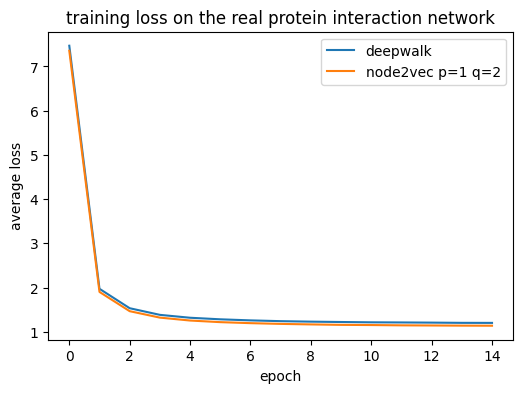

In [134]:
plt.figure(figsize=(6, 4))
plt.plot(ppi_deepwalk_history["epoch"], ppi_deepwalk_history["average_loss"], label="deepwalk")
plt.plot(ppi_node2vec_history["epoch"], ppi_node2vec_history["average_loss"], label="node2vec p=1 q=2")
plt.xlabel("epoch")
plt.ylabel("average loss")
plt.legend()
plt.title("training loss on the real protein interaction network")
plt.show()

evaluate embeddings with the exact protocol the papers use, multi label classification with macro and micro f1

In [135]:
from sklearn.linear_model import LogisticRegression
from sklearn.multiclass import OneVsRestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import f1_score

def evaluate_multilabel_classification(embeddings, labels, train_fraction, seed):
    node_indices = np.arange(embeddings.shape[0])
    train_indices, test_indices = train_test_split(node_indices, train_size=train_fraction, random_state=seed)
    classifier = OneVsRestClassifier(LogisticRegression(max_iter=1000))
    classifier.fit(embeddings[train_indices], labels[train_indices])
    predictions = classifier.predict(embeddings[test_indices])
    macro_f1 = f1_score(labels[test_indices], predictions, average="macro", zero_division=0)
    micro_f1 = f1_score(labels[test_indices], predictions, average="micro", zero_division=0)
    return macro_f1, micro_f1

compute macro and micro f1 for deepwalk and node2vec embeddings using half the nodes for training as in the papers headline table

In [136]:
ppi_deepwalk_embeddings = ppi_deepwalk_model.center_embeddings.weight.detach().numpy()
ppi_node2vec_embeddings = ppi_node2vec_model.center_embeddings.weight.detach().numpy()
ppi_deepwalk_macro_f1, ppi_deepwalk_micro_f1 = evaluate_multilabel_classification(ppi_deepwalk_embeddings, labels_ppi, 0.5, SEED)
ppi_node2vec_macro_f1, ppi_node2vec_micro_f1 = evaluate_multilabel_classification(ppi_node2vec_embeddings, labels_ppi, 0.5, SEED)
ppi_results_df = pd.DataFrame([
    {"method": "deepwalk", "final_loss": ppi_deepwalk_history["average_loss"][-1], "macro_f1": ppi_deepwalk_macro_f1, "micro_f1": ppi_deepwalk_micro_f1},
    {"method": "node2vec p=1 q=2", "final_loss": ppi_node2vec_history["average_loss"][-1], "macro_f1": ppi_node2vec_macro_f1, "micro_f1": ppi_node2vec_micro_f1}
])
ppi_results_df

,method,final_loss,macro_f1,micro_f1
0,deepwalk,1.201511,0.047565,0.057862
1,node2vec p=1 q=2,1.137505,0.033337,0.043812


interpret these numbers relative to a heavily reduced walk budget, not as a reproduction of the papers published scores